In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix
)

plt.rcParams.update({
    'figure.facecolor': '#f8f9fa',
    'axes.facecolor':   '#ffffff',
    'axes.spines.top':  False,
    'axes.spines.right': False,
    'font.size': 11,
})
COLORS = ['#4C72B0', '#DD8452', '#55A868']

print('All libraries imported successfully.')

All libraries imported successfully.


In [77]:
df = pd.read_csv('data/load_data.csv')
df.columns = [c.strip().replace('.', '_').replace(' ', '_') for c in df.columns]

df['Date_Time'] = pd.to_datetime(df['Date_Time'], format='%d-%m-%Y %H:%M')

# sort, and drop the one duplicated timestamp (31-12-2018 20:00)
df = (df.sort_values('Date_Time', kind='stable')
        .drop_duplicates('Date_Time', keep='first')
        .reset_index(drop=True))

MEASURES = ['Usage_kWh',
            'Lagging_Current_Reactive_Power_kVarh',
            'Leading_Current_Reactive_Power_kVarh',
            'CO2(tCO2)',
            'Lagging_Current_Power_Factor',
            'Leading_Current_Power_Factor']

# corrupted readings (more than 2 decimals) -> missing
for c in MEASURES:
    cents = df[c] * 100
    df.loc[(cents - cents.round()).abs() > 1e-6, c] = np.nan

# NSM is fully determined by the timestamp, so rebuild it
df['NSM'] = df['Date_Time'].dt.hour * 3600 + df['Date_Time'].dt.minute * 60

# fill gaps with the last valid reading (uses only the past)
df[MEASURES] = df[MEASURES].ffill().bfill()

df['month']      = df['Date_Time'].dt.month
df['hour']       = df['Date_Time'].dt.hour
df['minute']     = df['Date_Time'].dt.minute
df['dayofweek']  = df['Date_Time'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

le = LabelEncoder()
df['Load_Type_enc'] = le.fit_transform(df['Load_Type'])
print(f'Dataset shape : {df.shape}')
print(f'Date range    : {df["Date_Time"].min()} -> {df["Date_Time"].max()}')
print(f'\nClass label mapping:')
for i, cls in enumerate(le.classes_):
    n = (df['Load_Type_enc'] == i).sum()
    print(f'  {i} -> {cls}  ({n} records, {n/len(df)*100:.1f}%)')

Dataset shape : (35040, 15)
Date range    : 2018-01-01 00:00:00 -> 2018-12-31 23:45:00

Class label mapping:
  0 -> Light_Load  (18072 records, 51.6%)
  1 -> Maximum_Load  (7272 records, 20.8%)
  2 -> Medium_Load  (9696 records, 27.7%)


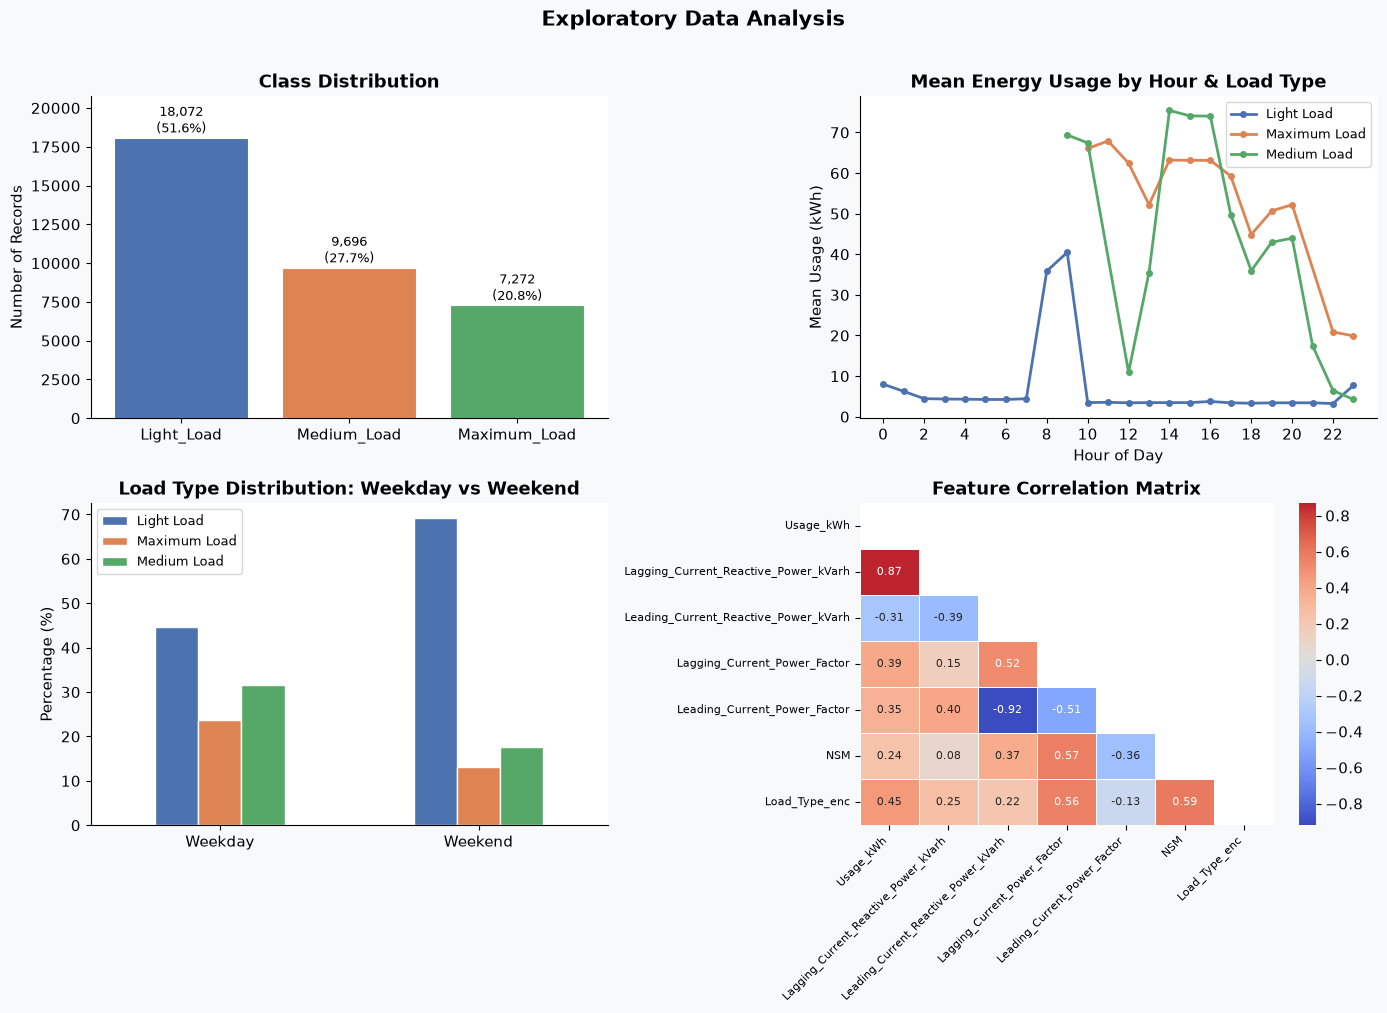

EDA complete.


In [78]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Exploratory Data Analysis', fontsize=15, fontweight='bold', y=1.01)

# Plot 1: Class Distribution
ax = axes[0, 0]
counts = df['Load_Type'].value_counts()
bars = ax.bar(counts.index, counts.values, color=COLORS, edgecolor='white', linewidth=0.8)
ax.set_title('Class Distribution', fontweight='bold')
ax.set_ylabel('Number of Records')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
            f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, counts.max() * 1.15)

# Plot 2: Mean Usage_kWh by Hour and Load Type
ax = axes[0, 1]
hourly = df.groupby(['hour', 'Load_Type'])['Usage_kWh'].mean().reset_index()
for i, lt in enumerate(le.classes_):
    d = hourly[hourly['Load_Type'] == lt]
    ax.plot(d['hour'], d['Usage_kWh'], marker='o', markersize=4,
            label=lt.replace('_', ' '), color=COLORS[i], linewidth=2)
ax.set_title('Mean Energy Usage by Hour & Load Type', fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Mean Usage (kWh)')
ax.legend(fontsize=9)
ax.set_xticks(range(0, 24, 2))

# Plot 3: Load Type by Weekday vs Weekend
ax = axes[1, 0]
weekend_dist = df.groupby(['is_weekend', 'Load_Type']).size().unstack(fill_value=0)
weekend_dist.index = ['Weekday', 'Weekend']
weekend_pct = weekend_dist.div(weekend_dist.sum(axis=1), axis=0) * 100
weekend_pct.plot(kind='bar', ax=ax, color=COLORS, edgecolor='white', width=0.5)
ax.set_title('Load Type Distribution: Weekday vs Weekend', fontweight='bold')
ax.set_ylabel('Percentage (%)')
ax.set_xlabel('')
ax.set_xticklabels(['Weekday', 'Weekend'], rotation=0)
ax.legend([c.replace('_', ' ') for c in weekend_pct.columns], fontsize=9)

# Plot 4: Correlation Heatmap
ax = axes[1, 1]
numeric_cols = ['Usage_kWh', 'Lagging_Current_Reactive_Power_kVarh',
                'Leading_Current_Reactive_Power_kVarh', 'CO2_tCO2_',
                'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor',
                'NSM', 'Load_Type_enc']
existing = [c for c in numeric_cols if c in df.columns]
corr = df[existing].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Feature Correlation Matrix', fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=120, bbox_inches='tight')
plt.show()
print('EDA complete.')

In [79]:
# ── Identify correct column names ──────────────────────────────────────────────────
print('Columns:', list(df.columns))

col_co2     = next((c for c in df.columns if 'CO2' in c), None)
col_lagging = next((c for c in df.columns if 'Lagging' in c and 'kVarh' in c), None)
col_leading = next((c for c in df.columns if 'Leading' in c and 'kVarh' in c), None)

print(f'CO2 column     : {col_co2}')
print(f'Lagging column : {col_lagging}')
print(f'Leading column : {col_leading}')

# ── Cyclical NSM encoding ────────────────────────────────────────────────
df['NSM_sin'] = np.sin(2 * np.pi * df['NSM'] / 86400)
df['NSM_cos'] = np.cos(2 * np.pi * df['NSM'] / 86400)

df['winter_schedule'] = df['month'].isin([11, 12, 1, 2]).astype(int)

# ── Lag features (past intervals only — no future leakage) ─────────────────────
df['Usage_lag1']  = df['Usage_kWh'].shift(1)    # 15 min ago
df['Usage_lag2']  = df['Usage_kWh'].shift(2)    # 30 min ago
df['Usage_lag4']  = df['Usage_kWh'].shift(4)    # 1 hour ago
df['Usage_lag12'] = df['Usage_kWh'].shift(12)   # 3 hours ago

# ── Rolling statistics (past window only — no future leakage) ──────────────────
df['Roll_mean_4']  = df['Usage_kWh'].shift(1).rolling(4).mean()    # 1h mean
df['Roll_max_12']  = df['Usage_kWh'].shift(1).rolling(12).max()    # 3h max
df['Roll_min_12']  = df['Usage_kWh'].shift(1).rolling(12).min()    # 3h min
df['Usage_diff_1'] = df['Usage_kWh'].diff(1)                       # momentum

df.dropna(subset=['Usage_lag12', 'Roll_mean_4',], inplace=True)
df.reset_index(drop=True, inplace=True)

# ── Final feature list ────────────────────────────────────────────────────
FEATURES = [
    # Assignment-specified (current interval sensor readings)
    'Usage_kWh',
    col_lagging,
    col_leading,
    col_co2,
    # Cyclical time encoding
    'NSM_sin', 'NSM_cos',
    # Calendar
    'hour', 'minute', 'dayofweek', 'is_weekend', 'winter_schedule',
    # Lag features (past usage history)
    'Usage_lag1', 'Usage_lag2', 'Usage_lag4', 'Usage_lag12',
    # Rolling statistics
    'Usage_diff_1', 'Roll_mean_4', 'Roll_max_12', 'Roll_min_12',

]

print(f'\nTotal features: {len(FEATURES)}')
for f in FEATURES:
    print(f'  - {f}')

Columns: ['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive_Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type', 'month', 'hour', 'minute', 'dayofweek', 'is_weekend', 'Load_Type_enc']
CO2 column     : CO2(tCO2)
Lagging column : Lagging_Current_Reactive_Power_kVarh
Leading column : Leading_Current_Reactive_Power_kVarh

Total features: 19
  - Usage_kWh
  - Lagging_Current_Reactive_Power_kVarh
  - Leading_Current_Reactive_Power_kVarh
  - CO2(tCO2)
  - NSM_sin
  - NSM_cos
  - hour
  - minute
  - dayofweek
  - is_weekend
  - winter_schedule
  - Usage_lag1
  - Usage_lag2
  - Usage_lag4
  - Usage_lag12
  - Usage_diff_1
  - Roll_mean_4
  - Roll_max_12
  - Roll_min_12


In [80]:
# ── Chronological Split ────────────────────────────────────────────────────
TRAIN_MONTHS = list(range(1, 12))   # January to November
TEST_MONTH   = 12                   # December (unseen)

train_df = df[df['month'].isin(TRAIN_MONTHS)].copy()
test_df  = df[df['month'] == TEST_MONTH].copy()

X_train = train_df[FEATURES]
y_train = train_df['Load_Type_enc']

X_test  = test_df[FEATURES]
y_test  = test_df['Load_Type_enc']

print(f'Train set (Jan-Nov) : {X_train.shape[0]:,} rows')
print(f'Test set  (Dec)     : {X_test.shape[0]:,} rows')
print(f'\nTrain class distribution:')
for i, cls in enumerate(le.classes_):
    n = (y_train == i).sum()
    print(f'  {cls}: {n} ({n/len(y_train)*100:.1f}%)')
print(f'\nTest class distribution (December):')
for i, cls in enumerate(le.classes_):
    n = (y_test == i).sum()
    print(f'  {cls}: {n} ({n/len(y_test)*100:.1f}%)')

Train set (Jan-Nov) : 32,052 rows
Test set  (Dec)     : 2,976 rows

Train class distribution:
  Light_Load: 16316 (50.9%)
  Maximum_Load: 6744 (21.0%)
  Medium_Load: 8992 (28.1%)

Test class distribution (December):
  Light_Load: 1744 (58.6%)
  Maximum_Load: 528 (17.7%)
  Medium_Load: 704 (23.7%)


In [81]:
# Scale features for logistic regression
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit only on train
X_test_sc  = scaler.transform(X_test)        # transform test with same scaler

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_sc, y_train)

y_pred_lr = lr.predict(X_test_sc)
acc_lr = accuracy_score(y_test, y_pred_lr)

print(f'Logistic Regression — December Test Accuracy: {acc_lr*100:.2f}%')
print()
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

Logistic Regression — December Test Accuracy: 73.42%

              precision    recall  f1-score   support

  Light_Load       0.89      1.00      0.94      1744
Maximum_Load       0.35      0.35      0.35       528
 Medium_Load       0.52      0.37      0.43       704

    accuracy                           0.73      2976
   macro avg       0.59      0.57      0.57      2976
weighted avg       0.71      0.73      0.72      2976



In [82]:
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Class weights to handle imbalance (Light=51%, Max=21%, Med=28%)
custom_weights = {0: 1.0, 1: 1.6, 2: 1.4}   # Light / Maximum / Medium

# ── LightGBM ───────────────────────────────────────────────────────────────
model_lgb = LGBMClassifier(
    n_estimators=600,
    learning_rate=0.012,
    max_depth=9,
    num_leaves=127,
    min_child_samples=35,
    class_weight=custom_weights,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# ── XGBoost ─────────────────────────────────────────────────────────────────
model_xgb = XGBClassifier(
    n_estimators=600,
    learning_rate=0.012,
    max_depth=7,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)
sample_weights_train = y_train.map(custom_weights)

print('Training LightGBM...')
model_lgb.fit(X_train, y_train)
print('LightGBM done.')

print('Training XGBoost...')
model_xgb.fit(X_train, y_train, sample_weight=sample_weights_train)
print('XGBoost done.')

# ── Soft probability ensemble ────────────────────────────────────────────────
final_probs_test = (
    model_lgb.predict_proba(X_test) +
    model_xgb.predict_proba(X_test)
) / 2.0

y_pred_ensemble = np.argmax(final_probs_test, axis=1)
acc_ensemble = accuracy_score(y_test, y_pred_ensemble)

print(f'\n{"="*55}')
print(f'LightGBM + XGBoost Ensemble — December Accuracy: {acc_ensemble*100:.2f}%')
print(f'{"="*55}')
print()
print(classification_report(y_test, y_pred_ensemble, target_names=le.classes_))

Training LightGBM...
LightGBM done.
Training XGBoost...
XGBoost done.

LightGBM + XGBoost Ensemble — December Accuracy: 97.95%

              precision    recall  f1-score   support

  Light_Load       0.98      0.99      0.98      1744
Maximum_Load       0.99      0.93      0.96       528
 Medium_Load       0.98      0.99      0.99       704

    accuracy                           0.98      2976
   macro avg       0.98      0.97      0.98      2976
weighted avg       0.98      0.98      0.98      2976



In [83]:
from sklearn.metrics import f1_score

print('Full Classification Report — LightGBM + XGBoost Ensemble (December):')
print(classification_report(y_test, y_pred_ensemble, target_names=le.classes_))

print('=' * 62)
print(f'{"Model":<42} {"Accuracy":>9} {"Macro-F1":>9}')
print('=' * 62)
for name, preds in [
    ('Logistic Regression (baseline)',  lr.predict(scaler.transform(X_test))),
    ('LightGBM + XGBoost Ensemble',     y_pred_ensemble),
]:
    acc = accuracy_score(y_test, preds)
    f1  = f1_score(y_test, preds, average='macro')
    print(f'{name:<42} {acc*100:>8.2f}% {f1:>9.3f}')
print('=' * 62)

Full Classification Report — LightGBM + XGBoost Ensemble (December):
              precision    recall  f1-score   support

  Light_Load       0.98      0.99      0.98      1744
Maximum_Load       0.99      0.93      0.96       528
 Medium_Load       0.98      0.99      0.99       704

    accuracy                           0.98      2976
   macro avg       0.98      0.97      0.98      2976
weighted avg       0.98      0.98      0.98      2976

Model                                       Accuracy  Macro-F1
Logistic Regression (baseline)                73.42%     0.574
LightGBM + XGBoost Ensemble                   97.95%     0.976


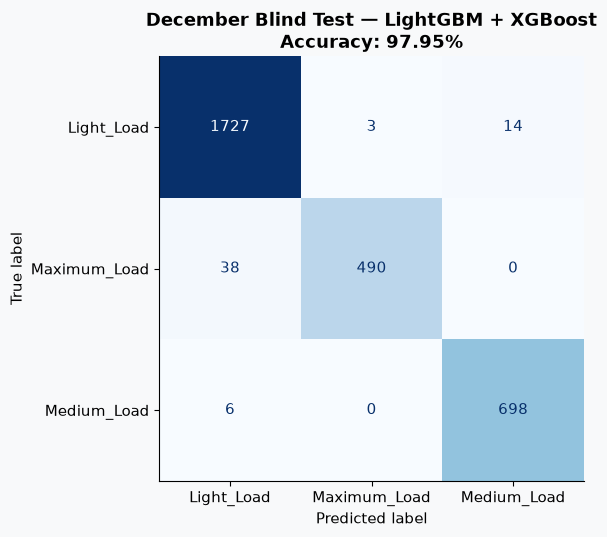

Confusion matrix saved.


In [84]:
fig, ax = plt.subplots(figsize=(7, 5.5))
cm = confusion_matrix(y_test, y_pred_ensemble)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(ax=ax, colorbar=False, cmap='Blues')
acc = accuracy_score(y_test, y_pred_ensemble)
ax.set_title(f'December Blind Test — LightGBM + XGBoost\nAccuracy: {acc*100:.2f}%', fontweight='bold')
plt.tight_layout()
plt.savefig('final_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()
print('Confusion matrix saved.')

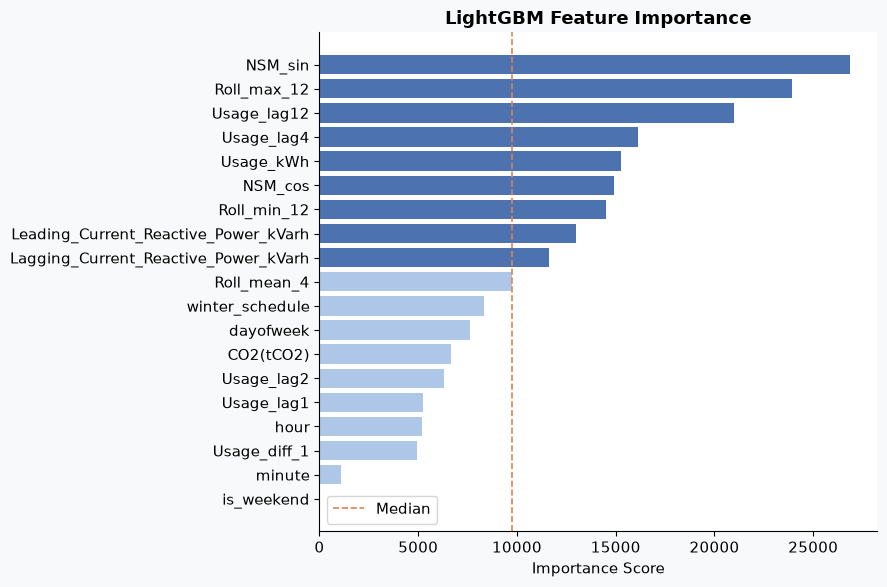

Feature importance chart saved.


In [85]:
# Feature Importance from LightGBM
importances = pd.Series(model_lgb.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(importances.index, importances.values,
               color=['#4C72B0' if v > importances.median() else '#AEC6E8'
                      for v in importances.values])
ax.set_title('LightGBM Feature Importance', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score')
ax.axvline(importances.median(), color='#DD8452', linestyle='--', linewidth=1.2, label='Median')
ax.legend()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()
print('Feature importance chart saved.')

1.Objective and validation strategy. Predict Load_Type; train on January–November and test on December; no shuffling.
2.Setup. Imports.
3.Data loading and cleaning. One duplicate timestamp removed. About 10% of each numeric column was corrupted, and values with more than 2 decimals were treated as corrupted (my inference from the data, not documented). NSM was rebuilt from the timestamp and gaps were filled with the last valid reading.
4.EDA. What each chart shows.
Feature engineering. Cyclical time, lags, rolling stats, and the winter flag (November–February runs a different daily schedule from March–October).
6.Train/test split. January–November vs December.
7.Baseline. Logistic regression, 73.42%.
8.Main model. LightGBM + XGBoost ensemble with averaged probabilities, 97.95%.
9.Results. Classification report and confusion matrix.
10.Feature importance.
11.Conclusions and limitations. One year of data, the corruption rule is an inference, the winter schedule was confirmed using December’s labels, and Maximum_Load recall is the weakest at 0.93.